# Question 3: Web Scraping the Eduvos qualifications, preprocess and summarise


In [13]:
# Run this block first

library(rvest)
library(httr)
library(stringr)
library(tm)
library(igraph)
library(ggplot2)

## Q3.1 Scrape the Eduvos website

In [14]:
base_url <- "https://www.eduvos.com"
ua <- user_agent("EduvosStudentProject/1.0 (non-commercial, educational)")

# fair use: check robots.txt, identify ourselves, and wait between requests
cat(httr::content(GET(paste0(base_url, "/robots.txt"), ua), "text", encoding = "UTF-8"))

get_page <- function(url) {
  Sys.sleep(2)
  read_html(GET(url, ua))
}

User-agent: *
Allow: /

User-agent: GPTBot
Allow: /

User-agent: ChatGPT-User
Allow: /

User-agent: OAI-SearchBot
Allow: /

User-agent: Google-Extended
Allow: /

User-agent: ClaudeBot
Allow: /

User-agent: PerplexityBot
Allow: /

Sitemap: https://www.eduvos.com/sitemap-ai.xml
Sitemap: https://www.eduvos.com/sitemap.xml


In [15]:
# the qualifications page links to one page per qualification
list_page <- get_page(paste0(base_url, "/qualifications/"))
links <- html_attr(html_elements(list_page, "a[href*='/programmes/']"), "href")
links <- unique(links[grepl("/programmes/.+", links) & !grepl("\\?", links)])
links <- ifelse(startsWith(links, "http"), links, paste0(base_url, links))

In [16]:
# open each qualification page and keep its title and paragraphs
qualifications <- data.frame(url = links, title = NA, text = NA)
for (i in seq_along(links)) {
  page <- tryCatch(get_page(links[i]), error = function(e) NULL)
  if (is.null(page)) { cat("Skipped (page not found):", links[i], "\n"); next }
  paragraphs <- html_text2(html_elements(page, "p"))
  qualifications$title[i] <- html_text2(html_element(page, "h1"))
  qualifications$text[i] <- paste(paragraphs[nchar(paragraphs) > 60], collapse = " ")
}
qualifications <- qualifications[!is.na(qualifications$text), ]    # drop the pages that were not found
print(qualifications[, c("title", "url")])
write.csv(qualifications, "Q3_1_qualifications.csv", row.names = FALSE)

Skipped (page not found): https://www.eduvos.com/programmes/bachelor-of-science-honours-in-information-technology-security-and-network-engineering/ 
                                                                                                         title
1                                                                                     Emeritus\nShort Courses.
2                                                                                     Emeritus\nShort Courses.
3                                                                       Bachelor of Arts Access Programme: ENG
4                                                            Bachelor of Commerce Access Programme: Accounting
5                                                 Bachelor of Science Access Programme: Information Technology
6                                                                Bachelor of Science Access Programme: Science
7                                                            Pre-degree Fo

## Q3.2 Text preprocessing

In [17]:
# split the text into sentences (bullet points count as separate sentences)
text <- str_replace_all(paste(qualifications$text, collapse = " "), "[•▪◦]", ". ")
sentences <- unique(unlist(str_split(text, "(?<=[.!?])\\s+(?=[A-Z])")))
sentences <- sentences[!grepl("credits", sentences)]               # drop the module lists
sentences <- str_replace_all(sentences, "[\\s.;]+\\.$", ".")        # remove stray endings such as ". ." and ";."
sentences <- sentences[str_count(sentences, "\\S+") %in% 8:60]      # keep sentences of 8 to 60 words
# lower case, letters only, remove stop words and very short words
clean <- function(s) {
  w <- strsplit(gsub("[^a-z ]", " ", tolower(s)), "\\s+")[[1]]
  w[nchar(w) > 2 & !(w %in% stopwords("en"))]
}
tokens <- lapply(sentences, clean)

cat("Sentences:", length(sentences), "\n")
cat("Words before:", sum(str_count(sentences, "\\S+")), " after:", sum(lengths(tokens)), "\n")
cat("Before:", sentences[1], "\nAfter: ", paste(tokens[[1]], collapse = " "), "\n")

Sentences: 485 
Words before: 10653  after: 6917 
Before: Eduvos is a private higher education institution in South Africa, registered with the DHET as Eduvos (Pty) Ltd (2001/HE07/008). 
After:  eduvos private higher education institution south africa registered dhet eduvos pty ltd 


## Q3.3 Summarisation: two techniques

In [18]:
# Technique 1: word frequency. A sentence scores high when it uses many frequent words.
freq <- sort(table(unlist(tokens)), decreasing = TRUE)
weight <- as.numeric(freq) / max(freq)
names(weight) <- names(freq)
score_freq <- sapply(tokens, function(w) mean(weight[w]))

In [19]:
# Technique 2: TextRank. Sentences that are similar to many other sentences score high.
tf <- t(sapply(tokens, function(w) as.numeric(table(factor(w, levels = names(freq))))))
sim <- cor(t(tf))                                                  # similarity between sentences
sim[is.na(sim) | sim < 0] <- 0
diag(sim) <- 0
score_rank <- page_rank(graph_from_adjacency_matrix(sim, mode = "undirected", weighted = TRUE))$vector

In [20]:
# the 5 best sentences of each technique, in the order they appear
top5 <- function(score) sort(order(score, decreasing = TRUE)[1:5])
cat("\nSUMMARY 1: word frequency\n"); cat(paste("-", sentences[top5(score_freq)]), sep = "\n")
cat("\nSUMMARY 2: TextRank\n");       cat(paste("-", sentences[top5(score_rank)]), sep = "\n")
writeLines(c("SUMMARY 1: word frequency", paste("-", sentences[top5(score_freq)]),
             "", "SUMMARY 2: TextRank", paste("-", sentences[top5(score_rank)])), "Q3_3_summaries.txt")


SUMMARY 1: word frequency
- International students are welcome to apply for this programme.
- Students develop an advanced level of knowledge and skills in the field of accounting.
- Students develop an advanced level of knowledge and skills in the field of human resources.
- Students develop an intermediate level of knowledge and skills in marketing.
- Students develop an advanced level of knowledge and skills in the field of tourism.

SUMMARY 2: TextRank
- It also provides an access pathway for students who do not meet the entry requirements for a degree and wish to apply for admission to an Eduvos Bachelor of Commerce programme after successfully completing the Higher Certificate, subject to the applicable admission requirements.
- Work Readiness Skills A and B support the development of critical thinking and practical workplace capabilities and enable students to apply knowledge acquired across the programme.
- Second-year-level modules are built on the foundation developed throug

### Findings: comparing the two summarisation techniques

The word frequency summary picks short sentences made of the most common words, such as "students", "programme", "knowledge" and "skills". It is easy to read but repetitive, because four of the five sentences are the same template with a different field of study. The TextRank summary picks longer sentences that are similar to many others, such as the access pathway into a degree, the work readiness skills and the structure of the years of study, so it gives more context. Only one sentence, the accounting one, appears in both summaries. Two of the TextRank sentences carry a footnote that starts with "*", which the simple sentence splitting does not separate.

## Q3.3 Visualisations

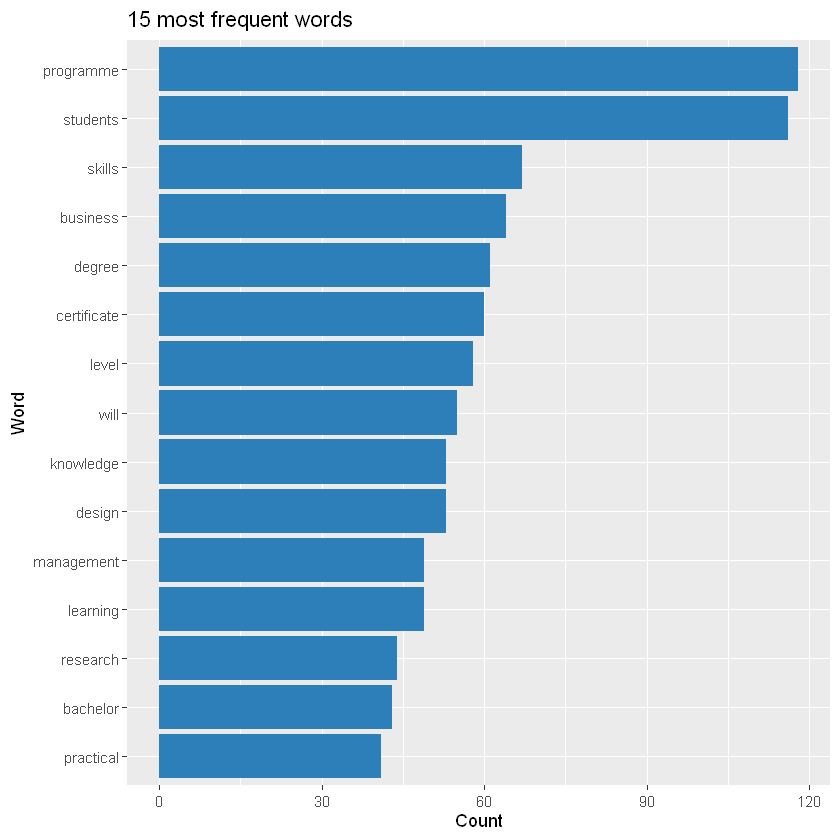

In [21]:
# Visualisation 1: the 15 most frequent words
top_words <- data.frame(word = names(freq)[1:15], count = as.numeric(freq)[1:15])
words_chart <- ggplot(top_words, aes(x = reorder(word, count), y = count)) +
  geom_col(fill = "#2C7FB8") + coord_flip() +
  labs(title = "15 most frequent words", x = "Word", y = "Count")
ggsave("Q3_3_top_words.png", words_chart, width = 8, height = 5)
print(words_chart)

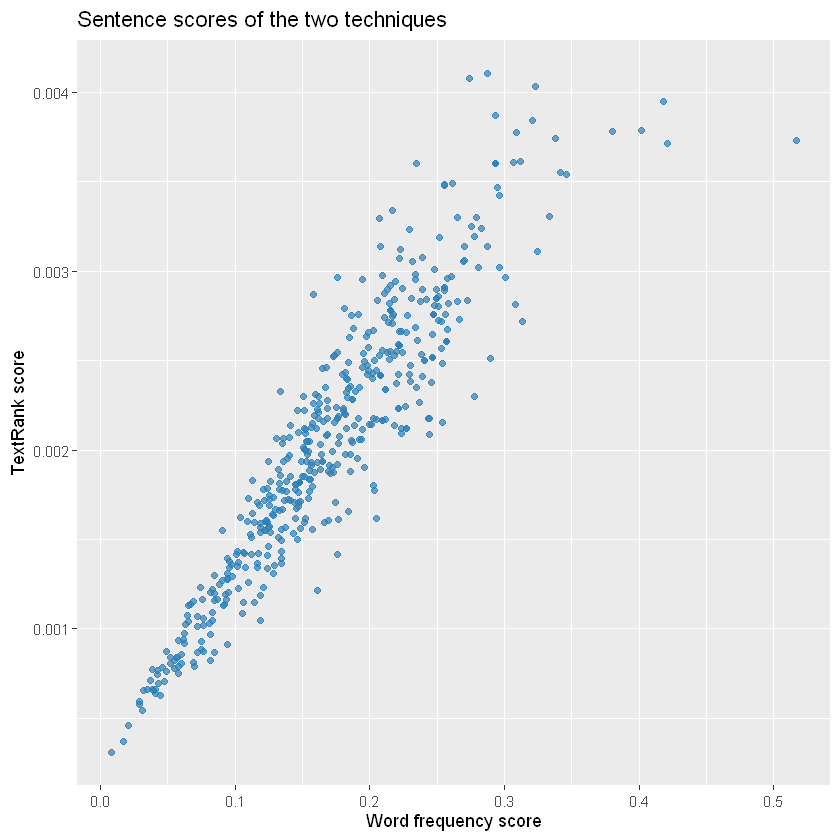

In [22]:
# Visualisation 2: the sentence scores of the two techniques compared
scores_chart <- ggplot(data.frame(freq = score_freq, rank = score_rank), aes(x = freq, y = rank)) +
  geom_point(colour = "#2C7FB8", alpha = 0.7) +
  labs(title = "Sentence scores of the two techniques", x = "Word frequency score", y = "TextRank score")
ggsave("Q3_3_sentence_scores.png", scores_chart, width = 8, height = 5)
print(scores_chart)

### Findings: visualisations

The bar chart shows that "programme" (118) and "students" (116) lead by a wide margin, followed by skills, business, degree and certificate. The text is mostly about programmes, the students who take them, the skills they build and the level of the qualification. The scatter plot rises from the bottom left to the top right, so a sentence that scores well with one technique usually scores well with the other (correlation 0.93). The points spread out at the top right, which is why the two summaries still pick different sentences.